**CS 4140 – Deep Learning · L04 · Why go deep?** &nbsp; [![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Bolufe-Rohler/4140-deep-learning/blob/main/lectures/L04_why-go-deep/L04_why_go_deep.ipynb)

Run the first code cell before anything else. In Colab, *File → Save a copy in Drive* keeps your own changes.

In [ ]:
# ▶ Run this cell first. It gets the course code and this lecture's saved results and data,
#   in Google Colab or on your own computer.
LECTURE = "L04_why-go-deep"
REPO = "https://github.com/Bolufe-Rohler/4140-deep-learning"
import os, sys, subprocess
root = os.path.abspath(os.path.join("..", ".."))
if not os.path.isfile(os.path.join(root, "cs4140_setup.py")):  # not inside the course repo (e.g. Colab)
    root = "/content/cs4140" if "google.colab" in sys.modules else os.path.abspath("cs4140")
    if not os.path.isdir(root):
        subprocess.run(["git", "clone", "--quiet", "--depth", "1", REPO, root], check=True)
    os.chdir(os.path.join(root, "lectures", LECTURE))
sys.path.insert(0, root)
import cs4140_setup
cs4140_setup.fetch_assets(LECTURE)

# CS 4140 · Lecture 4 · Why go deep?

On Jan 15 we changed the **width**, **depth** and **activation** of small networks on the two moons. Today we ask a sharper question:
with the **same number of parameters**, is a deep network better than a shallow one, and why were deep networks so hard to train before about 2010?

| Section | What it shows | Time |
|---|---|---|
| 1 | Parameter counts: width vs depth | instant |
| 2 | Two datasets: wide rings (easy) and narrow rings (hard) | instant |
| 3 | Same budget (~1,300 parameters): 1 hidden layer vs 4 hidden layers | ~80 s, or load saved weights |
| 4 | Five runs per setting: depth, and easy → hard rings (saved results) | instant, or ~45 min to recompute |
| 5 | Change the activation: vanishing gradients in a 10-layer network | ~40 s |
| 6 | Exercises | — |

Set `RUN_TRAINING = False` to load the saved weights in class. The figures are also on slides 21–23 of the deck.

In [1]:
import json, math, time
from pathlib import Path
import numpy as np
import torch
import torch.nn as nn
import matplotlib
import matplotlib.pyplot as plt
from matplotlib import font_manager
from sklearn.datasets import make_moons

RUN_TRAINING = True      # False: load rings_shallow.pt / rings_deep.pt (saved from this notebook)
RUN_SWEEP = False        # True: recompute section 4 (5 depths x 5 seeds, about 25 minutes on a laptop CPU)
N_SEEDS_ACT = 5          # runs per activation in section 5 (1 is enough in class)
HERE = Path('.')
FIG = HERE / 'figs'; FIG.mkdir(exist_ok=True)
torch.set_num_threads(1)   # tiny networks: one thread is fast enough and makes runs repeatable

# Slide-friendly figure style: the deck's serif font when it is installed
for fam in ['Century Schoolbook', 'TeX Gyre Schola', 'C059', 'DejaVu Serif']:
    if any(fam == f.name for f in font_manager.fontManager.ttflist):
        plt.rcParams['font.family'] = fam
        break
plt.rcParams.update({'font.size': 16, 'axes.spines.top': False, 'axes.spines.right': False})
NAVY, BLUE, RED, ORANGE, GREY = '#000080', '#0070C0', '#E00000', '#E69F00', '#808080'

def mlp(widths, act=nn.ReLU, init=None):
    # widths = [inputs, hidden_1, ..., hidden_L, outputs]
    layers = []
    for a, b in zip(widths[:-1], widths[1:]):
        layers += [nn.Linear(a, b), act()]
    model = nn.Sequential(*layers[:-1])          # no activation after the output layer
    if init == 'he':                              # He (Kaiming) initialization, made for ReLU
        for m in model:
            if isinstance(m, nn.Linear):
                nn.init.kaiming_normal_(m.weight, nonlinearity='relu'); nn.init.zeros_(m.bias)
    return model

def n_params(model):
    return sum(p.numel() for p in model.parameters())

def accuracy(model, X, y):
    with torch.no_grad():
        return ((model(X).squeeze(1) > 0).float() == y).float().mean().item()

print('PyTorch', torch.__version__)

PyTorch 2.14.1+cpu


## 1. Parameter counts: width vs depth

A `Linear(a, b)` layer has `a·b` weights and `b` biases. Widening a single hidden layer adds parameters **linearly** (each new unit costs `inputs + outputs + 1`);
a new hidden layer of width `w` costs about `w²`. So for a fixed budget, a deep network must be **narrow**.

In [2]:
archs = {
    '1 hidden layer  (2-330-1)':          [2, 330, 1],
    '2 hidden layers (2-34-34-1)':        [2, 34, 34, 1],
    '3 hidden layers (2-24-24-24-1)':     [2, 24, 24, 24, 1],
    '4 hidden layers (2-20-20-20-20-1)':  [2, 20, 20, 20, 20, 1],
    '6 hidden layers (2-16x6-1)':         [2] + [16] * 6 + [1],
}
for name, w in archs.items():
    print(f'{name:38s} {n_params(mlp(w)):6,d} parameters')
print()
print('Widening:  2-H-1 has 4H+1 parameters      ->', [n_params(mlp([2, H, 1])) for H in (10, 100, 1000)])
print('Deepening: 2-16x(L)-1 has ~272 per layer  ->', [n_params(mlp([2] + [16] * L + [1])) for L in (1, 2, 4, 8)])

1 hidden layer  (2-330-1)               1,321 parameters
2 hidden layers (2-34-34-1)             1,327 parameters
3 hidden layers (2-24-24-24-1)          1,297 parameters
4 hidden layers (2-20-20-20-20-1)       1,341 parameters
6 hidden layers (2-16x6-1)              1,425 parameters

Widening:  2-H-1 has 4H+1 parameters      -> [41, 401, 4001]
Deepening: 2-16x(L)-1 has ~272 per layer  -> [65, 337, 881, 1969]


## 2. Two datasets: wide rings and narrow rings

Points uniform in the square [−1, 1]²; the label alternates in concentric bands around the origin. `k` sets how narrow the bands are (band width 1/(k√2)):
`k = 2` gives a few wide rings, `k = 6` and `k = 8` many narrow ones. Sections 3 and 4 use `k = 6` unless they say otherwise. 3,000 training points; a fresh 3,000 for testing.

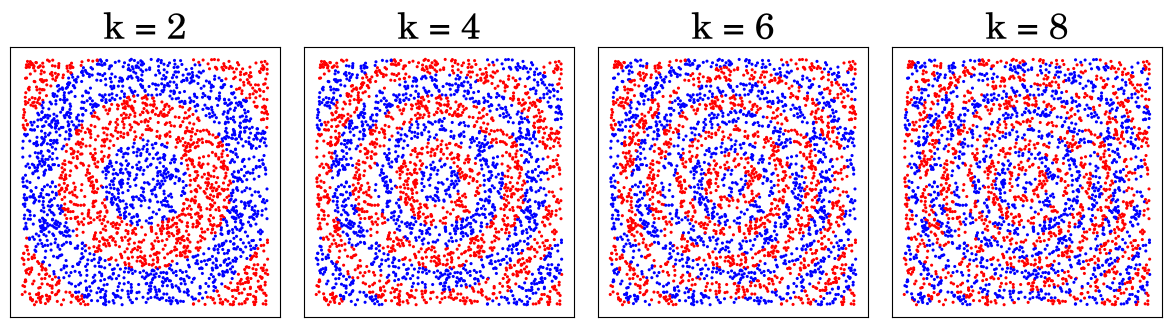

In [3]:
def make_rings(n=3000, seed=0, k=6):
    g = np.random.default_rng(seed)
    X = g.uniform(-1, 1, (n, 2))
    r = np.sqrt((X ** 2).sum(1))
    y = np.floor(r * k * np.sqrt(0.5) * 2) % 2
    return torch.tensor(X, dtype=torch.float32), torch.tensor(y, dtype=torch.float32)

fig, axes = plt.subplots(1, 4, figsize=(12, 3.4))
for ax, k in zip(axes, (2, 4, 6, 8)):
    X, y = make_rings(k=k)
    ax.scatter(X[:, 0], X[:, 1], c=y, cmap='bwr', s=1.5)
    ax.set_title(f'k = {k}', fontsize=26)
    ax.set_aspect('equal'); ax.set_xticks([]); ax.set_yticks([])
    for sp in ax.spines.values(): sp.set_visible(True)
plt.tight_layout(); fig.savefig(FIG / 'rings_datasets.png', dpi=200, bbox_inches='tight'); plt.show()

## 3. Same budget, shallow vs deep (narrow rings)

Both models get about 1,300 parameters and exactly the same training: Adam, learning rate 0.003, 8,000 full-batch steps, seed 1.
(Seed 1 is the median run of both models in section 4, so this pair is typical.)

In [4]:
def train_rings(widths, k=6, seed=1, steps=8000, lr=3e-3, verbose=False):
    X, y = make_rings(seed=0, k=k)
    torch.manual_seed(seed)
    model = mlp(widths)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.BCEWithLogitsLoss()
    for step in range(steps):
        opt.zero_grad()
        loss = loss_fn(model(X).squeeze(1), y)
        loss.backward()
        opt.step()
        if verbose and step % 2000 == 0:
            print(f'  step {step:5d}  loss {loss.item():.3f}')
    return model

SHALLOW, DEEP = [2, 330, 1], [2, 20, 20, 20, 20, 1]
Xtr, ytr = make_rings(seed=0, k=6)
Xte, yte = make_rings(seed=1, k=6)

if RUN_TRAINING:
    t0 = time.time()
    shallow = train_rings(SHALLOW); deep = train_rings(DEEP)
    torch.save(shallow.state_dict(), 'rings_shallow.pt'); torch.save(deep.state_dict(), 'rings_deep.pt')
    print(f'trained both in {time.time() - t0:.0f} s')
else:
    shallow, deep = mlp(SHALLOW), mlp(DEEP)
    shallow.load_state_dict(torch.load('rings_shallow.pt')); deep.load_state_dict(torch.load('rings_deep.pt'))

for name, m in (('shallow', shallow), ('deep', deep)):
    print(f'{name:8s} {n_params(m):5,d} parameters   train {accuracy(m, Xtr, ytr):.1%}   test {accuracy(m, Xte, yte):.1%}')

trained both in 46 s
shallow  1,321 parameters   train 76.8%   test 68.4%
deep     1,341 parameters   train 83.8%   test 77.6%


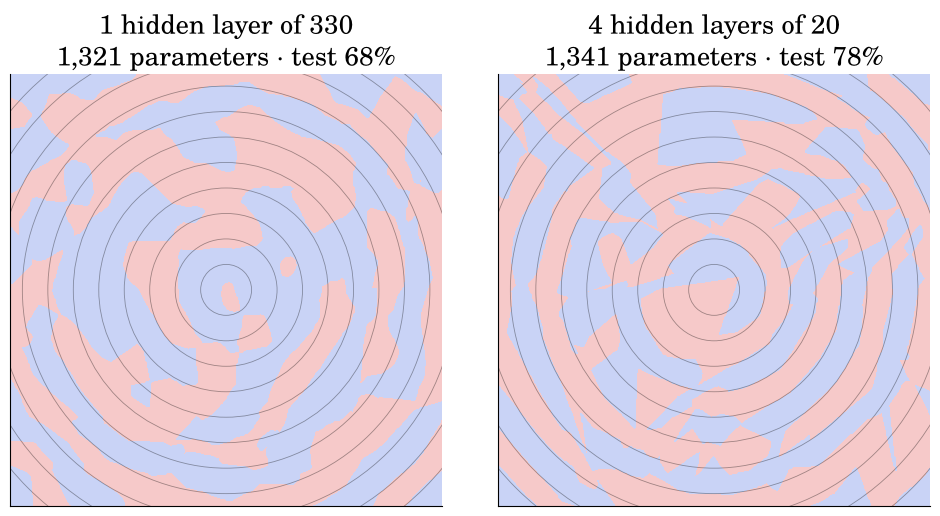

In [5]:
def boundary(ax, model, title):
    g = torch.linspace(-1, 1, 400)
    xx, yy = torch.meshgrid(g, g, indexing='xy')
    with torch.no_grad():
        zz = model(torch.stack([xx.ravel(), yy.ravel()], 1)).reshape(xx.shape) > 0
    ax.contourf(xx, yy, zz.float(), levels=[-0.5, 0.5, 1.5], colors=['#F6C9C9', '#C9D3F6'])
    # the true ring boundaries, for reference
    r = np.arange(1, 13) / (6 * np.sqrt(2))
    for ri in r:
        ax.add_patch(plt.Circle((0, 0), ri, fill=False, lw=0.6, color='k', alpha=0.35))
    ax.set_xlim(-1, 1); ax.set_ylim(-1, 1); ax.set_aspect('equal'); ax.set_xticks([]); ax.set_yticks([])
    ax.set_title(title, fontsize=19)

fig, axes = plt.subplots(1, 2, figsize=(10, 5.2))
boundary(axes[0], shallow, f'1 hidden layer of 330\n{n_params(shallow):,} parameters · test {accuracy(shallow, Xte, yte):.0%}')
boundary(axes[1], deep,    f'4 hidden layers of 20\n{n_params(deep):,} parameters · test {accuracy(deep, Xte, yte):.0%}')
plt.tight_layout(); fig.savefig(FIG / 'rings_boundaries.png', dpi=200, bbox_inches='tight'); plt.show()

**What to notice.** Each hidden ReLU unit of the shallow network adds one straight crease, and 330 short creases have to tile 12 circles piece by piece: the regions come out as blobs.
The deep network can fold the plane and fold the folds, so later layers reuse the same creases in several places. Its regions follow the rings further out, and the reuse is visible as straight streaks that repeat across the picture.

## 4. Five runs per setting (saved results)

Same data and training as section 3, about 1,300 parameters per model, seeds 0–4. Two sweeps:

* **depth** on the narrow rings (k = 6): 1, 2, 3, 4 and 6 hidden layers;
* **ring width** for the two models of section 3 (1 vs 4 hidden layers): k = 2, 4, 6 and 8.

`RUN_SWEEP = True` recomputes both (about 45 minutes on a laptop CPU); otherwise the saved `rings_depth_sweep.json` is loaded. It was produced with this same code.

In [6]:
DEPTHS = {1: [2, 330, 1], 2: [2, 34, 34, 1], 3: [2, 24, 24, 24, 1], 4: [2, 20, 20, 20, 20, 1], 6: [2] + [16] * 6 + [1]}
KS = (2, 4, 6, 8)

def five_runs(widths, k):
    Xa, ya = make_rings(seed=0, k=k); Xb, yb = make_rings(seed=1, k=k)
    ms = [train_rings(widths, k=k, seed=s) for s in range(5)]
    return [[accuracy(m, Xa, ya), accuracy(m, Xb, yb)] for m in ms]

if RUN_SWEEP:
    res = {'hard': {}, 'k': {'1': {}, '4': {}}}
    for depth, w in DEPTHS.items():
        res['hard'][str(depth)] = five_runs(w, 6); print('depth', depth, 'done')
    for depth in (1, 4):
        for k in KS:
            res['k'][str(depth)][str(k)] = res['hard'][str(depth)] if k == 6 else five_runs(DEPTHS[depth], k)
    json.dump(res, open('rings_depth_sweep.json', 'w'), indent=1)
else:
    res = json.load(open('rings_depth_sweep.json'))

test = lambda runs: [te for _, te in runs]
print('Narrow rings (k = 6), test accuracy over 5 runs')
for depth, w in DEPTHS.items():
    te = test(res['hard'][str(depth)])
    print(f'  {depth} hidden layer(s) {n_params(mlp(w)):6,d} params   mean {np.mean(te):.1%}   range {min(te):.1%}–{max(te):.1%}')
print('Ring width, mean test accuracy over 5 runs (1 hidden layer of 330  vs  4 hidden layers of 20)')
for k in KS:
    a, b = test(res['k']['1'][str(k)]), test(res['k']['4'][str(k)])
    print(f'  k = {k}:  {np.mean(a):.1%}  vs  {np.mean(b):.1%}    (ranges {min(a):.0%}–{max(a):.0%} and {min(b):.0%}–{max(b):.0%})')

Narrow rings (k = 6), test accuracy over 5 runs
  1 hidden layer(s)  1,321 params   mean 68.6%   range 66.6%–70.5%
  2 hidden layer(s)  1,327 params   mean 69.2%   range 65.7%–73.3%
  3 hidden layer(s)  1,297 params   mean 75.2%   range 68.8%–80.3%
  4 hidden layer(s)  1,341 params   mean 77.3%   range 71.5%–84.9%
  6 hidden layer(s)  1,425 params   mean 77.7%   range 74.5%–80.5%
Ring width, mean test accuracy over 5 runs (1 hidden layer of 330  vs  4 hidden layers of 20)
  k = 2:  97.8%  vs  98.4%    (ranges 97%–98% and 98%–99%)
  k = 4:  93.7%  vs  89.6%    (ranges 92%–95% and 87%–94%)
  k = 6:  68.6%  vs  77.3%    (ranges 67%–70% and 72%–85%)
  k = 8:  57.6%  vs  62.4%    (ranges 56%–59% and 60%–64%)


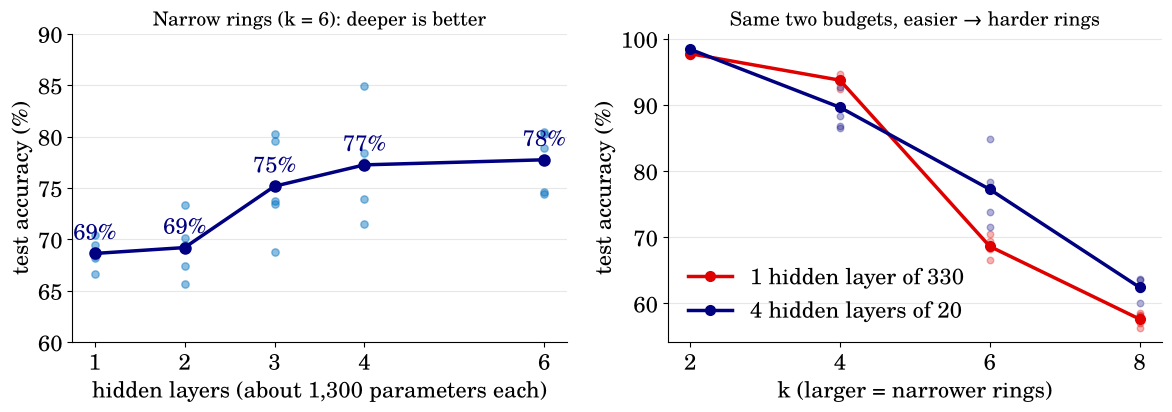

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
ax = axes[0]
for d in DEPTHS:
    ax.scatter([d] * 5, [100 * t for t in test(res['hard'][str(d)])], color=BLUE, alpha=0.45, s=28, zorder=2)
means = [100 * np.mean(test(res['hard'][str(d)])) for d in DEPTHS]
ax.plot(list(DEPTHS), means, '-o', color=NAVY, lw=2.5, ms=8, zorder=3)
for d, m in zip(DEPTHS, means):
    ax.annotate(f'{m:.0f}%', (d, m), textcoords='offset points', xytext=(0, 10), ha='center', color=NAVY)
ax.set_xticks(list(DEPTHS)); ax.set_xlabel('hidden layers (about 1,300 parameters each)')
ax.set_ylabel('test accuracy (%)'); ax.set_ylim(60, 90); ax.grid(axis='y', alpha=0.3)
ax.set_title('Narrow rings (k = 6): deeper is better', fontsize=14)
ax = axes[1]
for depth, col, lab in ((1, RED, '1 hidden layer of 330'), (4, NAVY, '4 hidden layers of 20')):
    ys = [100 * np.mean(test(res['k'][str(depth)][str(k)])) for k in KS]
    for k in KS:
        ax.scatter([k] * 5, [100 * t for t in test(res['k'][str(depth)][str(k)])], color=col, alpha=0.3, s=22)
    ax.plot(KS, ys, '-o', color=col, lw=2.5, ms=7, label=lab)
ax.set_xticks(KS); ax.set_xlabel('k (larger = narrower rings)'); ax.set_ylabel('test accuracy (%)')
ax.set_title('Same two budgets, easier → harder rings', fontsize=14)
ax.legend(frameon=False); ax.grid(axis='y', alpha=0.3)
plt.tight_layout(); fig.savefig(FIG / 'rings_sweeps.png', dpi=200, bbox_inches='tight'); plt.show()

**Read it carefully.** At the same budget, depth helps on the narrow rings (k = 6 and 8), ties on the wide ones (k = 2), and *loses* at k = 4, where 330 straight creases are enough and the narrow deep network is harder to train (its runs vary more).
Depth is not a free win: it pays off when the function has structure that can be built from reused pieces (repeated rings here; edges → parts → objects in images), and only if training finds it.

## 5. Change the activation: why deep networks were hard to train

Ten hidden layers of 16 units on the two moons from Jan 15, trained with plain gradient descent (SGD, learning rate 0.1, 2,000 full-batch steps).
First we look at the size of the gradient that reaches each layer **before training**.

In [8]:
Xm, ym = make_moons(1000, noise=0.15, random_state=0)
Xm = torch.tensor(Xm, dtype=torch.float32); ym = torch.tensor(ym, dtype=torch.float32)
Xm = (Xm - Xm.mean(0)) / Xm.std(0)
DEPTH, WIDTH = 10, 16
CONFIGS = {'sigmoid (default init)': (nn.Sigmoid, None),
           'ReLU (default init)':    (nn.ReLU, None),
           'ReLU + He init':         (nn.ReLU, 'he')}

def grad_profile(act, init, seeds=range(10)):
    norms = []
    for s in seeds:
        torch.manual_seed(s)
        m = mlp([2] + [WIDTH] * DEPTH + [1], act, init)
        nn.BCEWithLogitsLoss()(m(Xm).squeeze(1), ym).backward()
        norms.append([l.weight.grad.norm().item() for l in m if isinstance(l, nn.Linear)])
    return np.exp(np.mean(np.log(norms), 0))     # geometric mean over 10 random starts

profiles = {name: grad_profile(*cfg) for name, cfg in CONFIGS.items()}
for name, p in profiles.items():
    print(f'{name:24s} layer 1: {p[0]:.1e}   last layer: {p[-1]:.1e}   ratio {p[-1] / p[0]:.0e}')

sigmoid (default init)   layer 1: 8.3e-10   last layer: 1.0e-01   ratio 1e+08
ReLU (default init)      layer 1: 1.6e-05   last layer: 1.6e-02   ratio 1e+03
ReLU + He init           layer 1: 9.4e-02   last layer: 2.3e-01   ratio 2e+00


In [9]:
def train_moons(act, init, seed, steps=2000, lr=0.1):
    torch.manual_seed(seed)
    m = mlp([2] + [WIDTH] * DEPTH + [1], act, init)
    opt = torch.optim.SGD(m.parameters(), lr=lr); loss_fn = nn.BCEWithLogitsLoss(); curve = []
    for _ in range(steps):
        opt.zero_grad(); loss = loss_fn(m(Xm).squeeze(1), ym); loss.backward(); opt.step(); curve.append(loss.item())
    return accuracy(m, Xm, ym), curve

t0 = time.time()
acts = {}
for name, (act, init) in CONFIGS.items():
    runs = [train_moons(act, init, s) for s in range(N_SEEDS_ACT)]
    acts[name] = runs
    print(f'{name:24s} training accuracy: ' + '  '.join(f'{a:.1%}' for a, _ in runs) + f'    final loss (seed 0) {runs[0][1][-1]:.3f}')
print(f'({time.time() - t0:.0f} s)')

sigmoid (default init)   training accuracy: 50.0%  50.0%  50.0%  50.0%  50.0%    final loss (seed 0) 0.693


ReLU (default init)      training accuracy: 73.1%  62.2%  43.3%  29.8%  67.3%    final loss (seed 0) 0.693


ReLU + He init           training accuracy: 99.5%  99.3%  99.6%  99.2%  99.2%    final loss (seed 0) 0.013
(37 s)


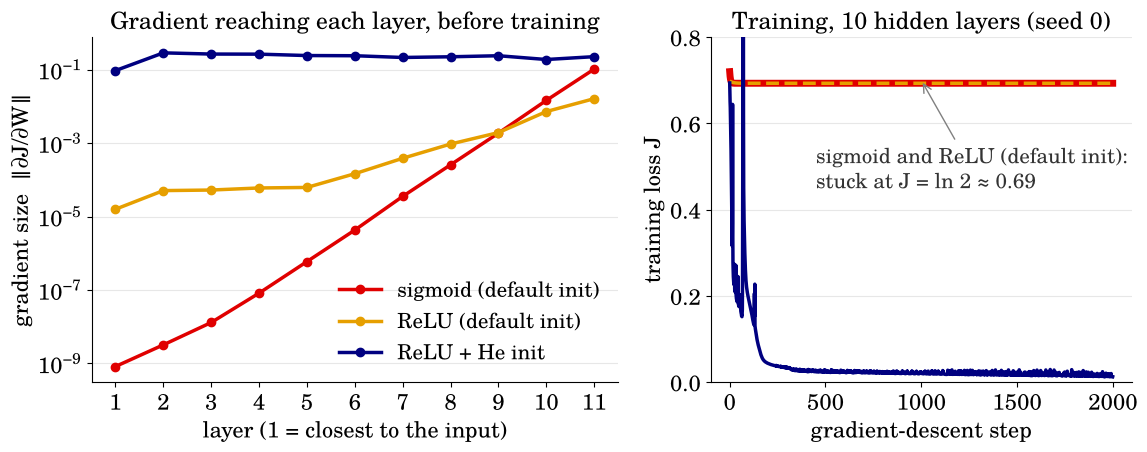

In [10]:
colors = {'sigmoid (default init)': RED, 'ReLU (default init)': ORANGE, 'ReLU + He init': NAVY}
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), gridspec_kw={'width_ratios': [1.25, 1]})
ax = axes[0]
layers = np.arange(1, DEPTH + 2)
for name, p in profiles.items():
    ax.semilogy(layers, p, '-o', color=colors[name], lw=2.5, ms=6, label=name)
ax.set_xlabel('layer (1 = closest to the input)'); ax.set_ylabel('gradient size  ‖∂J/∂W‖')
ax.set_xticks(layers); ax.set_title('Gradient reaching each layer, before training', fontsize=17)
ax.legend(frameon=False, fontsize=15, loc='lower right'); ax.grid(axis='y', alpha=0.3)
ax = axes[1]
styles = {'sigmoid (default init)': dict(lw=5, ls='-'), 'ReLU (default init)': dict(lw=2.5, ls='--'), 'ReLU + He init': dict(lw=2.5, ls='-')}
for name, runs in acts.items():                  # sigmoid and default-init ReLU overlap at J = ln 2 = 0.693: the network outputs a constant
    ax.plot(runs[0][1], color=colors[name], label=name, **styles[name])
ax.annotate('sigmoid and ReLU (default init):\nstuck at J = ln 2 ≈ 0.69', (1000, 0.70), xytext=(450, 0.45), fontsize=15,
            arrowprops=dict(arrowstyle='->', color=GREY), color='#333333')
ax.set_xlabel('gradient-descent step'); ax.set_ylabel('training loss J'); ax.set_ylim(0, 0.8)
ax.set_title('Training, 10 hidden layers (seed 0)', fontsize=17); ax.grid(axis='y', alpha=0.3)
plt.tight_layout(); fig.savefig(FIG / 'vanishing_gradients.png', dpi=200, bbox_inches='tight'); plt.show()

# the left panel alone, larger, for the slide
fig, ax = plt.subplots(figsize=(7.6, 4.7))
for name, p in profiles.items():
    ax.semilogy(layers, p, '-o', color=colors[name], lw=3, ms=7, label=name)
ax.set_xlabel('layer (1 = closest to the input)'); ax.set_ylabel('gradient size  ‖∂J/∂W‖')
ax.set_xticks(layers); ax.set_title('Gradient reaching each layer, before training', fontsize=17)
ax.legend(frameon=False, fontsize=15, loc='lower right'); ax.grid(axis='y', alpha=0.3)
plt.tight_layout(); fig.savefig(FIG / 'vanishing_gradients_slide.png', dpi=200, bbox_inches='tight'); plt.close(fig)

**What to notice.** With sigmoid units the gradient shrinks by a factor of about 10⁸ from the last layer to the first (σ′(z) ≤ 0.25 at every layer), and the loss never leaves ln 2 ≈ 0.69: the network outputs the same value for every point (50% accuracy).
ReLU passes gradients through unchanged where it is active, but PyTorch's default initialization is too small for ReLU, so they still shrink about 1,000-fold and the loss does not move either (the 30–73% accuracies are chance-level noise around a constant output).
ReLU with He initialization (He et al., 2015) keeps the gradient roughly the same size in every layer, and all runs reach about 99%.

## 6. Exercises (after class)

1. **Budget.** Give the shallow network four times the parameters (`[2, 1320, 1]`). Does it catch the deep one on the narrow rings?
2. **Width of the deep network.** Try `[2, 8, 8, 8, 8, 8, 1]` (321 parameters) on the narrow rings and run 5 seeds. What happens to the spread between seeds?
3. **tanh.** Add `'tanh': (nn.Tanh, None)` to `CONFIGS`. Does the 10-layer tanh network train with SGD? Why might a zero-centred activation with tanh′(0) = 1 behave differently from the sigmoid?
4. **Optimizer.** Train the 10-layer sigmoid network with `torch.optim.Adam(m.parameters(), lr=1e-2)` instead of SGD. What changes, and why might per-parameter step sizes help here?